# TabNet using LATAM-DDoS-IoT

In [1]:
!pip install pytorch-tabnet

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [3]:
balanced_ddos = pd.read_csv('balanced_global_dataset_ddos.csv')
balanced_ddos

,StartTime,TotPkts,TotBytes,LastTime,Seq,Dur,Mean,StdDev,Sum,Min,Max,SrcPkts,DstPkts,SrcBytes,DstBytes,Rate,SrcRate,DstRate,Category,Subcategory
0,22:47:00.737089,1,144,22:47:00.737089,1,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,1,0,144,0,0.000000,0.000000,0.000000,0,0
1,22:47:00.738627,3,354,22:47:00.758563,2,0.019936,0.019936,0.0,0.019936,0.019936,0.019936,2,1,132,222,100.321022,50.160511,0.000000,0,0
2,22:47:00.741855,2,248,22:47:00.741855,3,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,2,0,248,0,0.000000,0.000000,0.000000,0,0
3,22:47:00.741898,2,248,22:47:00.741899,4,0.000001,0.000001,0.0,0.000001,0.000001,0.000001,2,0,248,0,1000000.000000,1000000.000000,0.000000,0,0
4,22:47:00.742268,2,248,22:47:00.742269,5,0.000001,0.000001,0.0,0.000001,0.000001,0.000001,2,0,248,0,1000000.000000,1000000.000000,0.000000,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2431448,14:40:14.599334,2,248,14:40:14.599335,13456,0.000001,0.000001,0.0,0.000001,0.000001,0.000001,2,0,248,0,1000000.000000,1000000.000000,0.000000,1,3
2431449,14:40:14.696045,24,2416,14:40:14.700509,4366,0.004464,0.004464,0.0,0.004464,0.004464,0.004464,14,10,1260,1156,5152.329590,2912.186279,2016.129028,1,3
2431450,14:40:14.699737,4,264,14:40:14.699905,3345,0.000168,0.000168,0.0,0.000168,0.000168,0.000168,2,2,132,132,17857.142578,5952.380859,5952.380859,1,3
2431451,14:40:14.699738,4,264,14:40:14.699906,5672,0.000168,0.000168,0.0,0.000168,0.000168,0.000168,2,2,132,132,17857.142578,5952.380859,5952.380859,1,3


In [4]:
# Binary classification

balanced_ddos.Category.value_counts()

Category
1    1632266
0     799187
Name: count, dtype: int64

In [5]:
# Multiclass classification

np.unique(balanced_ddos.Subcategory)

array([0, 1, 2, 3])

In [6]:
balanced_ddos.iloc[3000]

StartTime      22:47:11.701635
TotPkts                     24
TotBytes                  2340
LastTime       22:47:11.714952
Seq                        371
Dur                   0.013317
Mean                  0.013317
StdDev                     0.0
Sum                   0.013317
Min                   0.013317
Max                   0.013317
SrcPkts                     14
DstPkts                     10
SrcBytes                  1164
DstBytes                  1176
Rate               1727.115723
SrcRate             976.195801
DstRate             675.827881
Category                     0
Subcategory                  0
Name: 3000, dtype: object

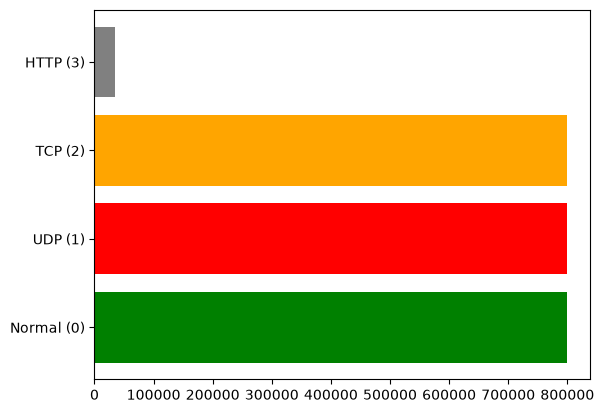

In [7]:
plt.barh(np.unique(balanced_ddos.Subcategory),
        balanced_ddos.Subcategory.value_counts(),
        color=["green", "red", "orange", "gray"])
plt.yticks([0, 1, 2, 3], ["Normal (0)", "UDP (1)", "TCP (2)", "HTTP (3)"])
plt.show();

In [8]:
balanced_ddos.dtypes

StartTime          str
TotPkts          int64
TotBytes         int64
LastTime           str
Seq              int64
Dur            float64
Mean           float64
StdDev         float64
Sum            float64
Min            float64
Max            float64
SrcPkts          int64
DstPkts          int64
SrcBytes         int64
DstBytes         int64
Rate           float64
SrcRate        float64
DstRate        float64
Category         int64
Subcategory      int64
dtype: object

In [9]:
balanced_ddos.drop(columns=["StartTime", "LastTime", "Seq", "StdDev"], inplace=True)

In [10]:
balanced_ddos.dtypes

TotPkts          int64
TotBytes         int64
Dur            float64
Mean           float64
Sum            float64
Min            float64
Max            float64
SrcPkts          int64
DstPkts          int64
SrcBytes         int64
DstBytes         int64
Rate           float64
SrcRate        float64
DstRate        float64
Category         int64
Subcategory      int64
dtype: object

In [11]:
y = balanced_ddos[['Category', 'Subcategory']]
X = balanced_ddos.drop(columns=['Category', 'Subcategory'])

In [12]:
X

,TotPkts,TotBytes,Dur,Mean,Sum,Min,Max,SrcPkts,DstPkts,SrcBytes,DstBytes,Rate,SrcRate,DstRate
0,1,144,0.000000,0.000000,0.000000,0.000000,0.000000,1,0,144,0,0.000000,0.000000,0.000000
1,3,354,0.019936,0.019936,0.019936,0.019936,0.019936,2,1,132,222,100.321022,50.160511,0.000000
2,2,248,0.000000,0.000000,0.000000,0.000000,0.000000,2,0,248,0,0.000000,0.000000,0.000000
3,2,248,0.000001,0.000001,0.000001,0.000001,0.000001,2,0,248,0,1000000.000000,1000000.000000,0.000000
4,2,248,0.000001,0.000001,0.000001,0.000001,0.000001,2,0,248,0,1000000.000000,1000000.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2431448,2,248,0.000001,0.000001,0.000001,0.000001,0.000001,2,0,248,0,1000000.000000,1000000.000000,0.000000
2431449,24,2416,0.004464,0.004464,0.004464,0.004464,0.004464,14,10,1260,1156,5152.329590,2912.186279,2016.129028
2431450,4,264,0.000168,0.000168,0.000168,0.000168,0.000168,2,2,132,132,17857.142578,5952.380859,5952.380859
2431451,4,264,0.000168,0.000168,0.000168,0.000168,0.000168,2,2,132,132,17857.142578,5952.380859,5952.380859


In [13]:
y

,Category,Subcategory
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
...,...,...
2431448,1,3
2431449,1,3
2431450,1,3
2431451,1,3


In [14]:
X.describe()

,TotPkts,TotBytes,Dur,Mean,Sum,Min,Max,SrcPkts,DstPkts,SrcBytes,DstBytes,Rate,SrcRate,DstRate
count,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06
mean,2.339802e+01,4.749794e+03,3.365286e+00,3.365286e+00,3.365286e+00,3.365286e+00,3.365286e+00,2.132166e+01,2.076365e+00,3.223382e+03,1.526412e+03,5.569891e+04,3.296570e+04,1.132316e+04
std,2.862780e+02,3.185640e+05,2.155364e+00,2.155364e+00,2.155364e+00,2.155364e+00,2.155364e+00,2.276355e+02,5.972390e+01,1.712695e+04,3.030647e+05,3.143793e+05,1.646928e+05,9.540852e+04
min,1.000000e+00,6.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.000000e+00,5.280000e+02,6.989400e-02,6.989400e-02,6.989400e-02,6.989400e-02,6.989400e-02,4.000000e+00,0.000000e+00,2.640000e+02,0.000000e+00,5.397108e+00,4.800943e+00,0.000000e+00
50%,2.700000e+01,3.976000e+03,4.791707e+00,4.791707e+00,4.791707e+00,4.791707e+00,4.791707e+00,2.600000e+01,0.000000e+00,3.976000e+03,0.000000e+00,5.913212e+00,5.609048e+00,0.000000e+00
75%,2.900000e+01,4.312000e+03,4.894840e+00,4.894840e+00,4.894840e+00,4.894840e+00,4.894840e+00,2.900000e+01,1.000000e+00,4.312000e+03,1.320000e+02,1.513638e+01,6.158464e+00,0.000000e+00
max,7.300700e+04,8.413636e+07,4.999999e+00,4.999999e+00,4.999999e+00,4.999999e+00,4.999999e+00,5.788000e+04,1.524000e+04,6.911314e+06,8.022363e+07,5.000000e+06,3.000000e+06,3.000000e+06


In [15]:
from sklearn.preprocessing import StandardScaler

std_scaler = StandardScaler()
std_scaler.fit(X)
X_std = std_scaler.transform(X)
X_std

array([[-0.07823874, -0.01445799, -1.56135404, ..., -0.17717112,
        -0.20016481, -0.11868084],
       [-0.07125252, -0.01379878, -1.55210455, ..., -0.17685201,
        -0.19986024, -0.11868084],
       [-0.07474563, -0.01413152, -1.56135404, ..., -0.17717112,
        -0.20016481, -0.11868084],
       ...,
       [-0.06775941, -0.0140813 , -1.56127609, ..., -0.12036983,
        -0.16402249, -0.05629247],
       [-0.06775941, -0.0140813 , -1.56127609, ..., -0.12036983,
        -0.16402249, -0.05629247],
       [-0.06775941, -0.0140813 , -1.56126774, ..., -0.12586673,
        -0.16752013, -0.06233006]], shape=(2431453, 14))

In [16]:
pd.DataFrame(X_std).describe()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
count,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06,2.431453e+06
mean,-1.496216e-18,7.481080e-19,-9.575782e-17,-9.575782e-17,-9.575782e-17,-9.575782e-17,-9.575782e-17,1.496216e-18,5.984864e-18,0.000000e+00,-7.481080e-19,0.000000e+00,2.393946e-17,1.795459e-17
std,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
min,-7.823874e-02,-1.472167e-02,-1.561354e+00,-1.561354e+00,-1.561354e+00,-1.561354e+00,-1.561354e+00,-9.366580e-02,-3.476608e-02,-1.882052e-01,-5.036588e-03,-1.771711e-01,-2.001648e-01,-1.186808e-01
25%,-6.077319e-02,-1.325258e-02,-1.528926e+00,-1.528926e+00,-1.528926e+00,-1.528926e+00,-1.528926e+00,-7.609385e-02,-3.476608e-02,-1.727909e-01,-5.036588e-03,-1.771540e-01,-2.001357e-01,-1.186808e-01
50%,1.258211e-02,-2.429006e-03,6.618006e-01,6.618006e-01,6.618006e-01,6.618006e-01,6.618006e-01,2.055192e-02,-3.476608e-02,4.394352e-02,-5.036588e-03,-1.771523e-01,-2.001308e-01,-1.186808e-01
75%,1.956832e-02,-1.374272e-03,7.096501e-01,7.096501e-01,7.096501e-01,7.096501e-01,7.096501e-01,3.373088e-02,-1.802236e-02,6.356172e-02,-4.601038e-03,-1.771230e-01,-2.001274e-01,-1.186808e-01
max,2.549397e+02,2.640965e+02,7.584395e-01,7.584395e-01,7.584395e-01,7.584395e-01,7.584395e-01,2.541725e+02,2.551395e+02,4.033462e+02,2.647029e+02,1.572719e+01,1.801557e+01,3.132506e+01


In [17]:
X_std_train, X_std_test, y_std_train, y_std_test = train_test_split(X_std, y, test_size=0.2)

In [18]:
X_std_val, X_std_test, y_std_val, y_std_test = train_test_split(X_std_test, y_std_test, test_size=0.5)

In [19]:
X_std_ft, X_std_val, y_std_ft, y_std_val = train_test_split(X_std_val, y_std_val, test_size=0.5)

In [20]:
distribution = {
    'Pre-training': [X_std_train.shape[0], round(X_std_train.shape[0] * 100 / X.shape[0], 2)],
    'Fine-tuning': [X_std_ft.shape[0], round(X_std_ft.shape[0] * 100 / X.shape[0], 2)],
    'Validation': [X_std_val.shape[0], round(X_std_val.shape[0] * 100 / X.shape[0], 2)],
    'Testing': [X_std_test.shape[0], round(X_std_test.shape[0] * 100 / X.shape[0], 2)],
}

pd.DataFrame(distribution.items())

,0,1
0,Pre-training,"[1945162, 80.0]"
1,Fine-tuning,"[121572, 5.0]"
2,Validation,"[121573, 5.0]"
3,Testing,"[243146, 10.0]"


In [21]:
# The different Category classes are present in each subset

np.unique(y_std_train.Category), np.unique(y_std_val.Category), np.unique(y_std_ft.Category), np.unique(y_std_test.Category)

(array([0, 1]), array([0, 1]), array([0, 1]), array([0, 1]))

## Classification

In [ ]:
import torch

from pytorch_tabnet.pretraining import TabNetPretrainer
from pytorch_tabnet.tab_model import TabNetClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from sklearn.model_selection import RandomizedSearchCV
import matplotlib.pyplot as plt

In [23]:
X_std_train

array([[-7.47456293e-02, -1.42413911e-02, -1.55540980e+00, ...,
        -1.76922847e-01, -2.00164814e-01, -1.18680842e-01],
       [ 1.95683246e-02, -8.90852785e-04,  6.80553345e-01, ...,
        -1.77152688e-01, -2.00129630e-01, -1.18680842e-01],
       [ 1.95683246e-02, -8.90852785e-04,  6.16308970e-01, ...,
        -1.77152144e-01, -2.00128592e-01, -1.18680842e-01],
       ...,
       [ 1.60752152e-02, -1.37427223e-03,  7.00124983e-01, ...,
        -1.77153500e-01, -2.00131181e-01, -1.18680842e-01],
       [ 3.00476528e-02, -6.46003975e-04,  7.22979130e-01, ...,
        -1.77151092e-01, -2.00126584e-01, -1.18680842e-01],
       [-6.77594105e-02, -1.40812977e-02, -1.56125521e+00, ...,
        -1.32370104e-01, -1.71658190e-01, -6.94731169e-02]],
      shape=(1945162, 14))

In [ ]:
unsupervised_model = TabNetPretrainer(
    n_steps=3,
    gamma=2.0,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=0.2),
    scheduler_fn=torch.optim.lr_scheduler.ExponentialLR,
    scheduler_params={'gamma': 0.95},
    verbose=1
)

unsupervised_model.fit(
    X_train=X_std_train,
    eval_set=[X_std_val],
    max_epochs=100,
    patience=3,
    batch_size=1024,
    drop_last=False,
    pretraining_ratio=0.5,
)

/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 20.09161| val_0_unsup_loss_numpy: 0.6094300150871277|  0:02:37s
epoch 1  | loss: 3.14885 | val_0_unsup_loss_numpy: 1576.888427734375|  0:05:12s
epoch 2  | loss: 4.96715 | val_0_unsup_loss_numpy: 35125764.0|  0:07:48s
epoch 3  | loss: 0.38235 | val_0_unsup_loss_numpy: 0.6014599800109863|  0:10:24s
epoch 4  | loss: 1.59326 | val_0_unsup_loss_numpy: 1.0145299434661865|  0:13:01s
epoch 5  | loss: 0.86647 | val_0_unsup_loss_numpy: 695362688.0|  0:15:37s
epoch 6  | loss: 0.39229 | val_0_unsup_loss_numpy: 2157769.25|  0:18:14s

Early stopping occurred at epoch 6 with best_epoch = 3 and best_val_0_unsup_loss_numpy = 0.6014599800109863


/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


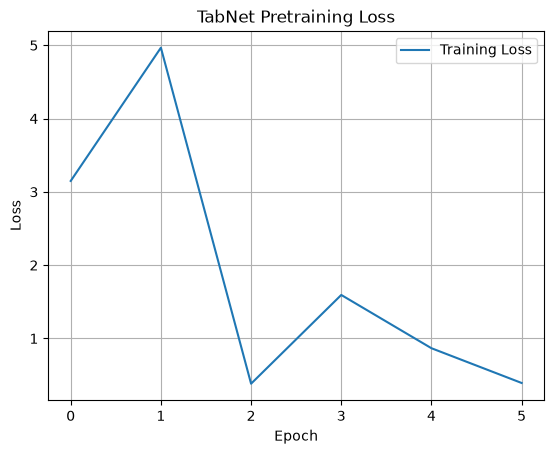

In [62]:

plt.plot(unsupervised_model.history['loss'][1:], label='Training Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('TabNet Pretraining Loss')
plt.legend()
plt.grid(True)

plt.show()

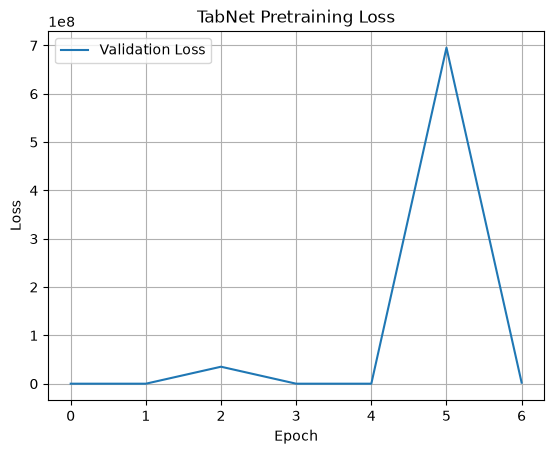

In [61]:

plt.plot(unsupervised_model.history['val_0_unsup_loss_numpy'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('TabNet Pretraining Loss')
plt.legend()
plt.grid(True)

plt.show()

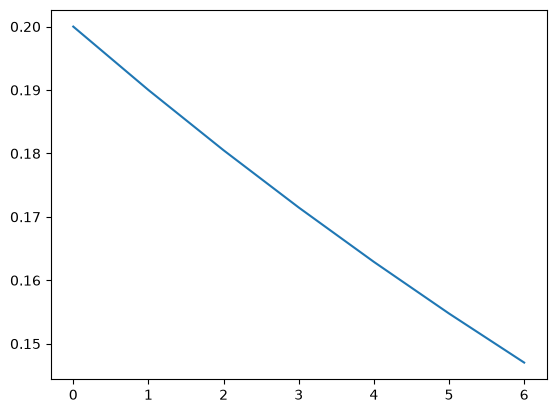

In [63]:
plt.plot(unsupervised_model.history['lr']);

In [64]:
# Feature Importance Masks

reconstructed_X, embedded_X = unsupervised_model.predict(X_std_val)
assert(reconstructed_X.shape==embedded_X.shape)

In [65]:
unsupervised_explain_matrix, unsupervised_masks = unsupervised_model.explain(X_std_val)

unsupervised_masks.keys(), unsupervised_masks[0].shape

(dict_keys([0, 1, 2]), (121573, 14))

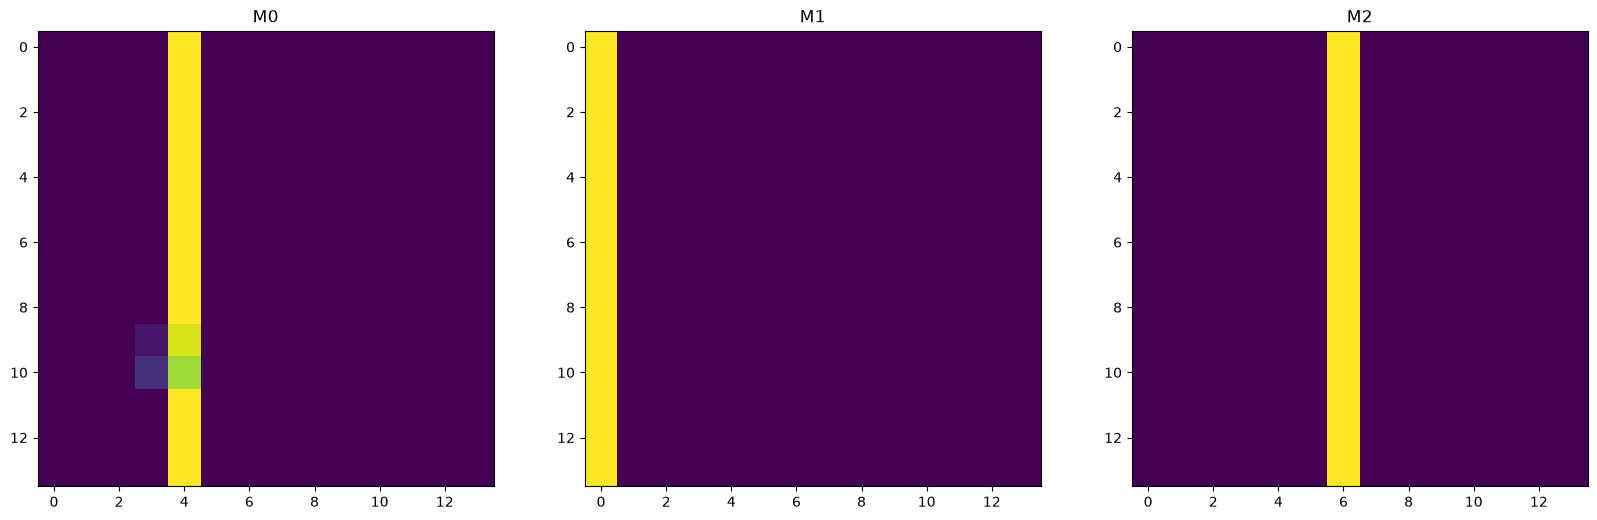

In [66]:
# Number of steps = Number of masks

fig, axs = plt.subplots(1, len(unsupervised_masks.keys()), figsize=(20,20))

for i in range(len(unsupervised_masks.keys())):
    axs[i].imshow(unsupervised_masks[i][:14])
    axs[i].set_title(f"M{i}")

In [67]:
unsupervised_explain_matrix.shape

(121573, 14)

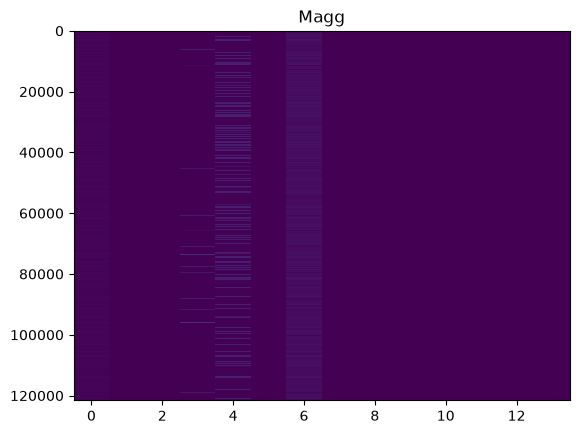

In [68]:
plt.imshow(unsupervised_explain_matrix, interpolation='nearest', aspect='auto')
plt.title('Magg');

In [69]:
unsupervised_model.save_model('ddos_tabnet')

loaded_pretrain = TabNetPretrainer()
loaded_pretrain.load_model('ddos_tabnet.zip')

Successfully saved model at ddos_tabnet.zip


/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


Optimización de hiperparametros, por cuestiones de memoria el batch_size lo mantuve en un maximo de 1024, sin embargo de acuerdo con el paper el modelo se beneficia de un batch_size mayor entre 1 a 10% de los datos. Mantuve las opciones de n_steps entre 3 y 10. Por tiempo solo probé 10 iteraciones, pero se obtuvo la mejor combinación entre los valores probados, Sin embargo se pudieran encontrar mejores valores con un batch size mayor, pero manteniendo el n_steps.

In [55]:
import torch
import pandas as pd
import numpy as np

from itertools import product
from sklearn.model_selection import ParameterSampler
from pytorch_tabnet.pretraining import TabNetPretrainer

# Define the hyperparameter distributions
param_distributions = {
    'batch_size': [256, 512, 1024],
    'n_steps': [3, 4, 5, 6, 7, 8, 9, 10]
}

# Configure randomized search
n_iter = 10  # Number of random combinations to evaluate
random_state = 42

# Randomly sample hyperparameter combinations
param_list = list(ParameterSampler(
    param_distributions,
    n_iter=n_iter,
    random_state=random_state
))

results = []

for i, params in enumerate(param_list, start=1):

    batch_size = params['batch_size']
    n_steps = params['n_steps']

    print(
        f"\nExperiment {i}/{n_iter}: "
        f"batch_size={batch_size}, n_steps={n_steps}"
    )

    # Initialize the model
    unsupervised_model = TabNetPretrainer(
        n_steps=n_steps,
        gamma=2.0,
        optimizer_fn=torch.optim.Adam,
        optimizer_params=dict(lr=0.2),
        scheduler_fn=torch.optim.lr_scheduler.ExponentialLR,
        scheduler_params={'gamma': 0.95},
        verbose=1
    )

    # Train the model
    unsupervised_model.fit(
        X_train=X_std_train,
        eval_set=[X_std_val],
        max_epochs=100,
        patience=3, #Lower patiente to avoid the overfitting in epoch 8
        batch_size=batch_size,
        drop_last=False,
        pretraining_ratio=0.5,
    )

    # Retrieve the best validation loss
    best_loss = min(
        unsupervised_model.history['val_0_unsup_loss_numpy']
    )

    # Record the results
    results.append({
        'batch_size': batch_size,
        'n_steps': n_steps,
        'best_val_loss': best_loss,
        'best_epoch': unsupervised_model.best_epoch
    })

# Create a DataFrame with the results
results_df = pd.DataFrame(results)

# Rank configurations by validation loss
results_df = results_df.sort_values(
    by='best_val_loss',
    ascending=True
).reset_index(drop=True)

print("\nRandom Search Results:")
print(results_df)

# Display the best configuration
best_params = results_df.iloc[0]

print("\nBest Hyperparameters:")
print(f"Batch Size: {best_params['batch_size']}")
print(f"N_steps: {best_params['n_steps']}")
print(f"Validation Loss: {best_params['best_val_loss']:.6f}")

# Save the results
results_df.to_csv(
    'tabnet_random_search_results.csv',
    index=False
)


Experiment 1/10: batch_size=512, n_steps=3


/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 70.8838 | val_0_unsup_loss_numpy: 291875136.0|  0:03:25s
epoch 1  | loss: 1.65063 | val_0_unsup_loss_numpy: 14761798656.0|  0:06:48s
epoch 2  | loss: 0.86235 | val_0_unsup_loss_numpy: 64787537920.0|  0:10:11s
epoch 3  | loss: 20.28148| val_0_unsup_loss_numpy: 38660584.0|  0:13:33s
epoch 4  | loss: 0.35697 | val_0_unsup_loss_numpy: 0.6270700097084045|  0:16:56s
epoch 5  | loss: 6.26072 | val_0_unsup_loss_numpy: 75964672.0|  0:20:19s
epoch 6  | loss: 0.72173 | val_0_unsup_loss_numpy: 0.6079999804496765|  0:23:40s
epoch 7  | loss: 12.90115| val_0_unsup_loss_numpy: 78768652288.0|  0:27:03s
epoch 8  | loss: 0.33493 | val_0_unsup_loss_numpy: 17925924864.0|  0:30:26s
epoch 9  | loss: 0.33669 | val_0_unsup_loss_numpy: 4344826368.0|  0:33:48s

Early stopping occurred at epoch 9 with best_epoch = 6 and best_val_0_unsup_loss_numpy = 0.6079999804496765

Experiment 2/10: batch_size=1024, n_steps=3


/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 20.09161| val_0_unsup_loss_numpy: 0.6094300150871277|  0:02:33s
epoch 1  | loss: 3.14885 | val_0_unsup_loss_numpy: 1576.888427734375|  0:05:08s
epoch 2  | loss: 4.96715 | val_0_unsup_loss_numpy: 35125764.0|  0:07:43s
epoch 3  | loss: 0.38235 | val_0_unsup_loss_numpy: 0.6014599800109863|  0:10:19s
epoch 4  | loss: 1.59326 | val_0_unsup_loss_numpy: 1.0145299434661865|  0:12:53s
epoch 5  | loss: 0.86647 | val_0_unsup_loss_numpy: 695362688.0|  0:15:28s
epoch 6  | loss: 0.39229 | val_0_unsup_loss_numpy: 2157769.25|  0:18:06s

Early stopping occurred at epoch 6 with best_epoch = 3 and best_val_0_unsup_loss_numpy = 0.6014599800109863

Experiment 3/10: batch_size=256, n_steps=3


/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


... (12 outputs left out)

epoch 0  | loss: 22.54294| val_0_unsup_loss_numpy: 480704.375|  0:05:35s
epoch 1  | loss: 5.69708 | val_0_unsup_loss_numpy: 523932160.0|  0:11:15s
epoch 2  | loss: 0.50224 | val_0_unsup_loss_numpy: 239384656.0|  0:16:53s
epoch 3  | loss: 0.99727 | val_0_unsup_loss_numpy: 82242760.0|  0:22:37s

Early stopping occurred at epoch 3 with best_epoch = 0 and best_val_0_unsup_loss_numpy = 480704.375

Experiment 10/10: batch_size=256, n_steps=8


/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)
/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 153.69253| val_0_unsup_loss_numpy: 24920906006528.0|  0:11:03s
epoch 1  | loss: 1279.41752| val_0_unsup_loss_numpy: 4176529326080.0|  0:22:07s
epoch 2  | loss: 549.08224| val_0_unsup_loss_numpy: 4186768640.0|  0:33:11s
epoch 3  | loss: 298.61882| val_0_unsup_loss_numpy: 3.806975723168596e+18|  0:44:18s
epoch 4  | loss: 3.45101 | val_0_unsup_loss_numpy: 8.353271311190983e+19|  0:55:26s
epoch 5  | loss: 10448.80596| val_0_unsup_loss_numpy: 4.009855574629312e+19|  1:06:36s

Early stopping occurred at epoch 5 with best_epoch = 2 and best_val_0_unsup_loss_numpy = 4186768640.0

Random Search Results:
   batch_size  n_steps  best_val_loss  best_epoch
0        1024        3   6.014649e-01           3
1         512        3   6.080040e-01           6
2         512        4   6.281342e-01           2
3         256        3   6.327982e-01           1
4        1024        5   6.338274e-01           0
5         512        8   6.521817e-01           4
6         256        4   4.7348

/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


Cambiar Learning Rate Scheduler.

In [70]:
unsupervised_model = TabNetPretrainer(
    n_steps=3,
    gamma=2.0,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=0.2),
    scheduler_fn=torch.optim.lr_scheduler.StepLR,
    scheduler_params={
        'step_size': 10,
        'gamma': 0.1
    },
    verbose=1
)

unsupervised_model.fit(
    X_train=X_std_train,
    eval_set=[X_std_val],
    max_epochs=100,
    patience=3,
    batch_size=1024,
    drop_last=False,
    pretraining_ratio=0.5,
)

/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 20.09161| val_0_unsup_loss_numpy: 0.6094300150871277|  0:04:19s
epoch 1  | loss: 42.43806| val_0_unsup_loss_numpy: 6.610300064086914|  0:07:02s
epoch 2  | loss: 13.73054| val_0_unsup_loss_numpy: 0.6174499988555908|  0:09:49s
epoch 3  | loss: 67.36283| val_0_unsup_loss_numpy: 77086.3671875|  0:12:38s

Early stopping occurred at epoch 3 with best_epoch = 0 and best_val_0_unsup_loss_numpy = 0.6094300150871277


/home/rampo/anaconda3/envs/pyML/lib/python3.13/site-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


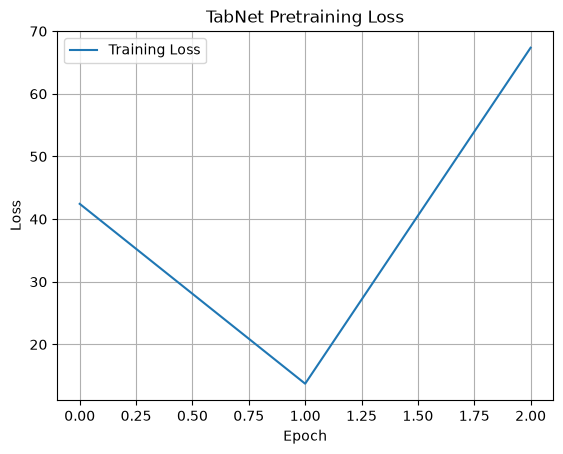

In [71]:
plt.plot(unsupervised_model.history['loss'][1:], label='Training Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('TabNet Pretraining Loss')
plt.legend()
plt.grid(True)

plt.show()

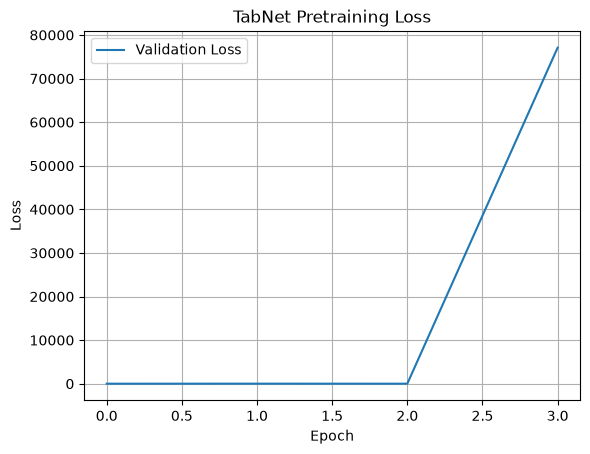

In [72]:

plt.plot(unsupervised_model.history['val_0_unsup_loss_numpy'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('TabNet Pretraining Loss')
plt.legend()
plt.grid(True)

plt.show()

In [74]:
# Feature Importance Masks

reconstructed_X, embedded_X = unsupervised_model.predict(X_std_val)
assert(reconstructed_X.shape==embedded_X.shape)

In [ ]:
unsupervised_explain_matrix, unsupervised_masks = unsupervised_model.explain(X_std_val)

unsupervised_masks.keys(), unsupervised_masks[0].shape

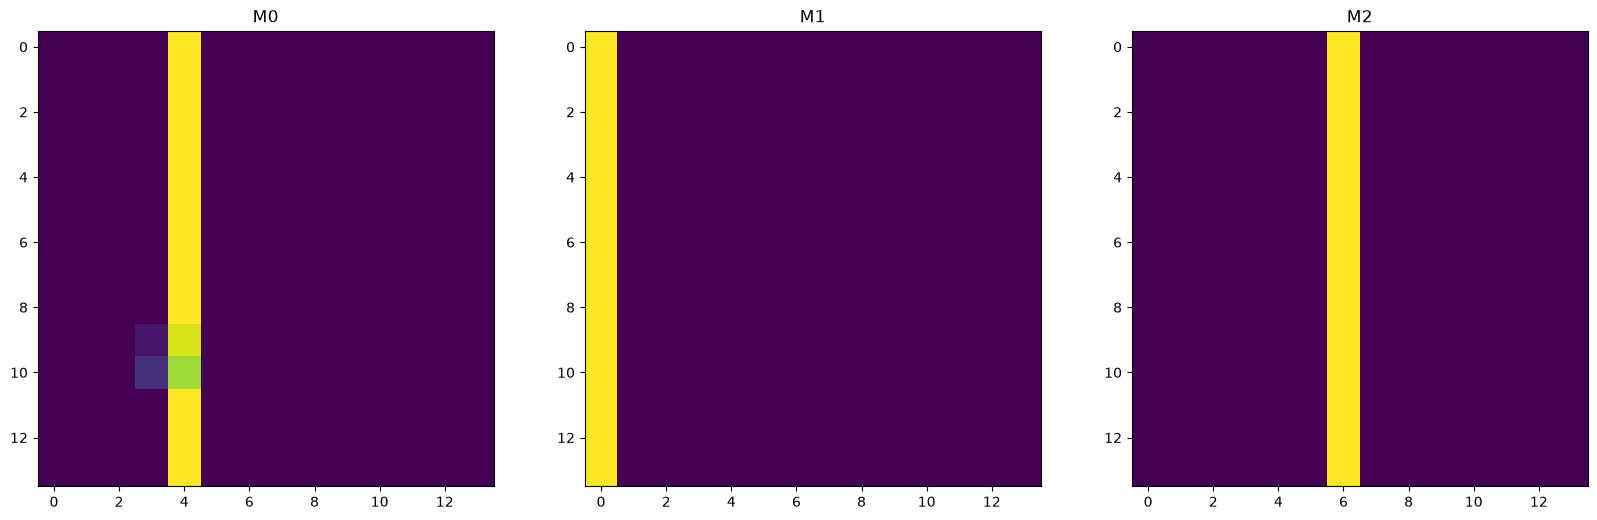

In [75]:
# Number of steps = Number of masks

fig, axs = plt.subplots(1, len(unsupervised_masks.keys()), figsize=(20,20))

for i in range(len(unsupervised_masks.keys())):
    axs[i].imshow(unsupervised_masks[i][:14])
    axs[i].set_title(f"M{i}")

In [76]:
unsupervised_explain_matrix.shape

(121573, 14)

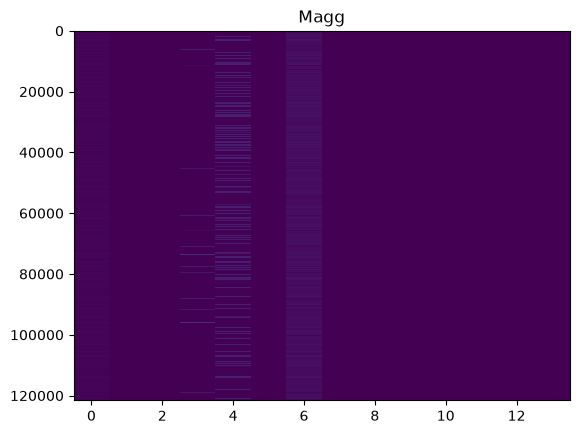

In [77]:
plt.imshow(unsupervised_explain_matrix, interpolation='nearest', aspect='auto')
plt.title('Magg');